---
title: "Sismicidad de Colombia"
author: Mauricio Romero
date: 2026-10-06
lang: es
format:
  html:
    code-fold: true
    code-summary: "Mostrar código"
    code-tools: true
execute:
  enabled: false
resources:
  - sismicidad-anim.webp
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/web/blob/main/grd/geologicas/sismicidad-colombia.ipynb)

Este cuaderno reconstruye, con datos abiertos y código ejecutable, la visualización de sismicidad de Colombia difundida en redes por *@notasdeungeologo* (mapa animado año a año y cortes Sur-Norte y Oeste-Este hasta 200 km con exageración vertical ×3), y le añade lo que a la pieza original le falta para leerse bien:

1. **Completitud del catálogo.** Cuántos sismos "aparecen" por mejor instrumentación y cuántos por actividad real.
2. **Tiempo a ritmo constante** y comparación lado a lado entre *todo el catálogo* y *solo magnitudes completas*.
3. **Cortes con referencia.** Escala horizontal, franjas por latitud en lugar de proyectar todo el país, y comparación ×3 frente a ×1.
4. **El sismo del 10 de agosto de 2026** (San José del Palmar, Chocó) ubicado dentro del corte.

**Fuentes.** El catálogo instrumental se descarga del servicio FDSN del USGS (ComCat) y los sismos anteriores a 1900 de la base de sismos significativos de NOAA/NCEI. El reel original parece usar el catálogo del Servicio Geológico Colombiano (SGC), que no tiene descarga programática pública; la sección 2.3 permite cargar una exportación propia del SGC. Por eso los conteos de este cuaderno son menores que los del video (el USGS registra sobre todo M ≳ 4 en la región), pero las conclusiones sobre completitud y geometría se sostienen.

## 1. Configuración

En Colab todas las dependencias ya están instaladas. Fuera de Colab: `pip install -r requirements.txt`.

In [1]:
from pathlib import Path
import io, json, time, warnings

import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap, Normalize

warnings.filterwarnings("ignore", category=UserWarning)

# ---------------- Parámetros ----------------
# Cuadrante del Catálogo Sísmico Integrado del SGC (Montejo et al., 2023)
BBOX = dict(lon_min=-84.0, lon_max=-66.0, lat_min=-5.0, lat_max=16.0)

ANIO_INI = 1900            # @param {type:"integer"}  inicio del catálogo instrumental
FECHA_FIN = "2026-09-30"   # @param {type:"string"}   fecha fija = resultado reproducible
MAG_MIN = 2.5              # @param {type:"number"}   magnitud mínima de descarga
MAG_COMPLETA = 4.5         # @param {type:"number"}   umbral "completo" para la animación
PROF_MAX = 200             # @param {type:"number"}   profundidad máxima de los cortes (km)
EXAG_VERTICAL = 3          # @param {type:"number"}   exageración vertical de los cortes
FORZAR_DESCARGA = False    # @param {type:"boolean"}  ignora la copia en data/
USAR_NOAA = True           # @param {type:"boolean"}  sismos históricos anteriores a ANIO_INI
RUTA_SGC = None            # p. ej. "data/sgc_export.csv" (ver sección 2.3)

# Sismo de referencia (parámetros reportados por el SGC)
EVENTO_REF = dict(nombre="San José del Palmar, 10-ago-2026", lat=4.99, lon=-76.29,
                  prof_km=103.0, mag=7.4)

DATA, FIG = Path("data"), Path("figuras")
DATA.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

ANIO_FIN = pd.Timestamp(FECHA_FIN).year + (pd.Timestamp(FECHA_FIN).dayofyear - 1) / 365.25
LAT_MEDIA = (BBOX["lat_min"] + BBOX["lat_max"]) / 2
KM_LAT = 110.57
KM_LON = 111.32 * np.cos(np.radians(LAT_MEDIA))

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

def miles(n):
    """Entero con punto como separador de miles."""
    return f"{int(n):,}".replace(",", ".")

def dec(x):
    """Número con coma decimal."""
    return f"{x:g}".replace(".", ",")

## 2. Datos

### 2.1 Catálogo instrumental (USGS ComCat)

La API devuelve como máximo 20.000 eventos por consulta, así que la descarga se hace por décadas y cualquier tramo saturado se divide en dos. El resultado se guarda en `data/` para no repetir la descarga; si ese archivo se sube al repositorio, la publicación en MyST no depende de la red.

In [2]:
USGS_URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
LIMITE = 20000

def _usgs_tramo(t0, t1):
    """Descarga un tramo temporal; si llega al límite, lo divide en dos."""
    params = dict(format="csv", orderby="time-asc", limit=LIMITE, eventtype="earthquake",
                  starttime=t0.strftime("%Y-%m-%dT%H:%M:%S"), endtime=t1.strftime("%Y-%m-%dT%H:%M:%S"),
                  minlatitude=BBOX["lat_min"], maxlatitude=BBOX["lat_max"],
                  minlongitude=BBOX["lon_min"], maxlongitude=BBOX["lon_max"],
                  minmagnitude=MAG_MIN)
    for intento in range(4):
        r = requests.get(USGS_URL, params=params, timeout=180)
        if r.status_code in (200, 204):
            break
        time.sleep(5 * (intento + 1))
    r.raise_for_status()
    if r.status_code == 204 or not r.text.strip():
        return pd.DataFrame()
    df = pd.read_csv(io.StringIO(r.text))
    if len(df) >= LIMITE:
        tm = t0 + (t1 - t0) / 2
        return pd.concat([_usgs_tramo(t0, tm), _usgs_tramo(tm, t1)], ignore_index=True)
    return df

def descargar_usgs():
    archivo = DATA / f"catalogo_usgs_{ANIO_INI}_{FECHA_FIN}_M{MAG_MIN}.csv"
    if archivo.exists() and not FORZAR_DESCARGA:
        print(f"Usando copia local: {archivo}")
        return pd.read_csv(archivo)
    partes, t, fin = [], pd.Timestamp(year=ANIO_INI, month=1, day=1), pd.Timestamp(FECHA_FIN)
    while t < fin:
        t2 = min(t + pd.DateOffset(years=10), fin)
        parte = _usgs_tramo(t, t2)
        print(f"  {t.year}–{t2.year}: {miles(len(parte))} eventos")
        partes.append(parte)
        t = t2
    df = pd.concat([p for p in partes if len(p)], ignore_index=True).drop_duplicates("id")
    df.to_csv(archivo, index=False)
    (DATA / "procedencia_usgs.json").write_text(json.dumps(
        dict(fuente=USGS_URL, descargado=pd.Timestamp.now(tz="UTC").isoformat(), bbox=BBOX,
             anio_ini=ANIO_INI, fecha_fin=FECHA_FIN, mag_min=MAG_MIN, eventos=len(df)), indent=2))
    return df

def normalizar_usgs(df):
    t = pd.to_datetime(df["time"], utc=True, format="ISO8601")
    dias = np.where(t.dt.is_leap_year, 366, 365)
    return pd.DataFrame({
        "anio_dec": t.dt.year + (t.dt.dayofyear - 1 + t.dt.hour / 24) / dias,
        "fecha": t.dt.strftime("%Y-%m-%d"),
        "lat": df["latitude"], "lon": df["longitude"], "prof_km": df["depth"],
        "mag": df["mag"], "tipo_mag": df["magType"], "lugar": df["place"],
        "fuente": "USGS", "historico": False,
    })

usgs = normalizar_usgs(descargar_usgs())
print(f"USGS: {miles(len(usgs))} eventos, {usgs.fecha.min()} a {usgs.fecha.max()}")

  1900–1910: 8 eventos


  1910–1920: 22 eventos


  1920–1930: 32 eventos


  1930–1940: 45 eventos


  1940–1950: 37 eventos


  1950–1960: 52 eventos


... (3 outputs left out)

  1990–2000: 2.425 eventos


  2000–2010: 2.048 eventos


  2010–2020: 2.065 eventos


  2020–2026: 1.731 eventos
USGS: 10.872 eventos, 1900-10-29 a 2026-09-29


### 2.2 Sismos históricos (NOAA/NCEI)

La base de sismos significativos de NOAA aporta los eventos preinstrumentales y, para todo el periodo, las víctimas reportadas. Eso permite etiquetar el mapa por **impacto** y no solo por magnitud. En los eventos históricos la magnitud proviene de intensidades macrosísmicas y la profundidad casi nunca se conoce: aquí se dejan sin profundidad en lugar de asignarles una por defecto.

Si el servicio no responde, el cuaderno continúa solo con el catálogo instrumental.

In [3]:
NOAA_URL = "https://www.ngdc.noaa.gov/hazel/hazard-service/api/v1/earthquakes"
COLS_NOAA = ["year", "month", "day", "latitude", "longitude", "eqDepth", "eqMagnitude",
             "locationName", "deaths"]

def descargar_noaa(pais="COLOMBIA"):
    archivo = DATA / f"noaa_significativos_{pais.lower()}.csv"
    if archivo.exists() and not FORZAR_DESCARGA:
        return pd.read_csv(archivo)
    filas, pag, total = [], 1, 1
    while pag <= total:
        r = requests.get(NOAA_URL, params=dict(country=pais, page=pag), timeout=120)
        r.raise_for_status()
        js = r.json()
        filas += js.get("items", [])
        total = int(js.get("totalPages", 1) or 1)
        pag += 1
    df = pd.DataFrame(filas).reindex(columns=COLS_NOAA)
    df.to_csv(archivo, index=False)
    return df

def normalizar_noaa(df):
    df = df.reindex(columns=COLS_NOAA)
    mes, dia = df["month"].fillna(7), df["day"].fillna(15)
    lugar = (df["locationName"].fillna("").astype(str)
             .str.split(":").str[-1].str.split(",").str[0].str.strip().str.title())
    fecha = (df["year"].astype("Int64").astype(str) + "-" + mes.astype(int).astype(str).str.zfill(2)
             + "-" + dia.astype(int).astype(str).str.zfill(2))
    return pd.DataFrame({
        "anio_dec": df["year"] + (mes - 1) / 12 + (dia - 1) / 365.25, "fecha": fecha,
        "lat": df["latitude"], "lon": df["longitude"], "prof_km": df["eqDepth"],
        "mag": df["eqMagnitude"], "tipo_mag": "macrosísmica/varios", "lugar": lugar,
        "fuente": "NOAA", "historico": df["year"] < ANIO_INI, "muertes": df["deaths"],
    })

noaa = pd.DataFrame()
if USAR_NOAA:
    try:
        noaa = normalizar_noaa(descargar_noaa())
        print(f"NOAA: {len(noaa)} sismos significativos, {int(noaa.anio_dec.min())}–{int(noaa.anio_dec.max())}")
    except Exception as e:
        print(f"No se pudo obtener la base de NOAA ({type(e).__name__}: {e}). Se continúa sin históricos.")

NOAA: 83 sismos significativos, 1566–2026


### 2.3 Opcional: catálogo del SGC

Para acercarse a los ~380.000 eventos del video hay que usar el catálogo de la Red Sismológica Nacional de Colombia. Se exporta manualmente desde la consulta del SGC (`bdrsnc.sgc.gov.co/paginas1/catalogo/`), se guarda como CSV en `data/` y se indica la ruta en `RUTA_SGC`. Ajuste `COLS_SGC` a los encabezados de su archivo. Si se define, este catálogo **reemplaza** al del USGS desde su primer año.

In [4]:
COLS_SGC = dict(fecha="FECHA", hora="HORA_UTC", lat="LATITUD (grados)", lon="LONGITUD (grados)",
                prof="PROFUNDIDAD (Km)", mag="MAGNITUD Ml", lugar="MUNICIPIO")

def cargar_sgc(ruta, cols=COLS_SGC):
    df = pd.read_csv(ruta)
    faltan = [v for k, v in cols.items() if v not in df.columns and k != "lugar"]
    if faltan:
        raise KeyError(f"Columnas no encontradas en {ruta}: {faltan}. Disponibles: {list(df.columns)}")
    t = pd.to_datetime(df[cols["fecha"]].astype(str) + " " + df[cols["hora"]].astype(str),
                       errors="coerce", utc=True)
    dias = np.where(t.dt.is_leap_year, 366, 365)
    out = pd.DataFrame({
        "anio_dec": t.dt.year + (t.dt.dayofyear - 1 + t.dt.hour / 24) / dias,
        "fecha": t.dt.strftime("%Y-%m-%d"),
        "lat": pd.to_numeric(df[cols["lat"]], errors="coerce"),
        "lon": pd.to_numeric(df[cols["lon"]], errors="coerce"),
        "prof_km": pd.to_numeric(df[cols["prof"]], errors="coerce"),
        "mag": pd.to_numeric(df[cols["mag"]], errors="coerce"),
        "tipo_mag": cols["mag"], "lugar": df.get(cols["lugar"], ""),
        "fuente": "SGC", "historico": False,
    })
    return out.dropna(subset=["anio_dec", "lat", "lon"])

instrumental = usgs
if RUTA_SGC:
    sgc = cargar_sgc(RUTA_SGC)
    corte_sgc = np.floor(sgc.anio_dec.min())
    instrumental = pd.concat([usgs[usgs.anio_dec < corte_sgc], sgc], ignore_index=True)
    print(f"SGC: {miles(len(sgc))} eventos desde {int(corte_sgc)}; USGS se conserva antes de ese año.")

### 2.4 Catálogo unificado

In [5]:
partes = [instrumental]
if len(noaa):
    partes.append(noaa[noaa.historico].drop(columns="muertes"))

cat = pd.concat(partes, ignore_index=True)
cat = cat[cat.lon.between(BBOX["lon_min"], BBOX["lon_max"]) & cat.lat.between(BBOX["lat_min"], BBOX["lat_max"])]
cat = cat.dropna(subset=["anio_dec", "lat", "lon", "mag"]).sort_values("anio_dec").reset_index(drop=True)
cat["anio"] = np.floor(cat.anio_dec).astype(int)
FUENTES = {"USGS": "USGS ComCat", "NOAA": "NOAA/NCEI", "SGC": "SGC-RSNC"}
CREDITO = "Datos: " + ", ".join(FUENTES[f] for f in sorted(cat.fuente.unique())) + "."

print(f"Catálogo unificado: {miles(len(cat))} eventos, {cat.anio.min()}–{cat.anio.max()}")
print(cat.groupby("fuente").agg(eventos=("mag", "size"), desde=("anio", "min"), hasta=("anio", "max"),
                                mag_min=("mag", "min"), mag_max=("mag", "max")))
print(f"Sin profundidad conocida: {miles(cat.prof_km.isna().sum())}")
cat.sort_values("mag", ascending=False).head(10)[["fecha", "mag", "tipo_mag", "prof_km", "lugar", "fuente"]]

Catálogo unificado: 10.884 eventos, 1566–2026
        eventos  desde  hasta  mag_min  mag_max
fuente                                         
NOAA         12   1566   1883      4.0      8.2
USGS      10872   1900   2026      2.5      8.8
Sin profundidad conocida: 10


,fecha,mag,tipo_mag,prof_km,lugar,fuente
16,1906-01-31,8.8,mw,20.00,1906 Ecuador-Colombia Earthquake,USGS
5,1826-06-18,8.2,macrosísmica/varios,NaN,Engativa,NOAA
307,1970-07-31,8.0,mw,644.80,"95 km N of San Antonio del Estrecho, Peru",USGS
48,1922-01-17,7.9,mw,475.00,"143 km ESE of San Antonio del Estrecho, Peru",USGS
0,1566-07-15,7.8,macrosísmica/varios,NaN,Colombia,NOAA
8183,2016-04-16,7.8,mww,20.59,"27 km SSE of Muisne, Ecuador",USGS
125,1942-05-14,7.8,mw,20.00,"12 km SE of Pedernales, Ecuador",USGS
1270,1979-12-12,7.7,ms,24.00,"56 km NW of Valdez, Ecuador",USGS
12,1900-10-29,7.7,mw,NaN,Near the coast of Venezuela,USGS
2880,1991-04-22,7.6,mw,10.00,"34 km S of Limón, Costa Rica",USGS


## 3. Completitud: ¿tiembla más o medimos mejor?

El contador del video pasa de 20 sismos en 1903 a 380.530 en 2026. La figura compara esa curva (leída del video fotograma a fotograma) con el acumulado de este catálogo para tres umbrales de magnitud. Si el crecimiento fuera actividad real, las tres curvas se dispararían por igual. Lo que se espera ver es que solo se dispara la de *todos los eventos*, con escalones en los años en que cambia la instrumentación.

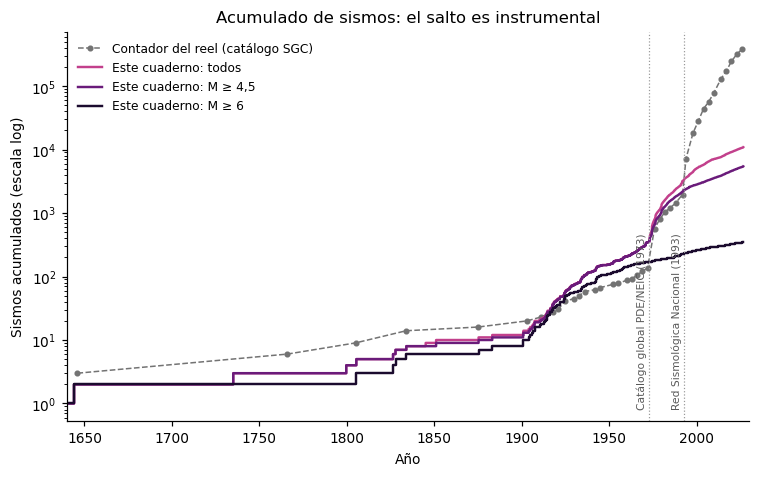

Eventos desde 1973: 96.7 % del catálogo
Eventos desde 1993: 68.6 % del catálogo
En el reel, eventos posteriores a 1992: 99.5 %


In [6]:
# Contador acumulado del reel (lectura por OCR del video original)
CONTADOR_REEL = {1646: 3, 1766: 6, 1805: 9, 1834: 14, 1875: 16, 1903: 20, 1911: 23, 1918: 28,
    1921: 31, 1925: 41, 1930: 45, 1933: 50, 1936: 58, 1942: 62, 1945: 67, 1952: 75, 1955: 78,
    1960: 87, 1963: 92, 1966: 105, 1969: 121, 1972: 137, 1976: 570, 1979: 800, 1982: 1042,
    1985: 1215, 1988: 1432, 1992: 1961, 1994: 7233, 1998: 18194, 2001: 28149, 2004: 43736,
    2007: 56872, 2010: 79084, 2014: 130222, 2017: 172634, 2020: 245954, 2023: 317410, 2026: 380530}

HITOS = {1973: "Catálogo global PDE/NEIC (1973)", 1993: "Red Sismológica Nacional (1993)"}

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(list(CONTADOR_REEL), list(CONTADOR_REEL.values()), "o--", ms=3, lw=1, color="0.45",
        label="Contador del reel (catálogo SGC)")
for umbral, color in [(None, "#c2408c"), (MAG_COMPLETA, "#6a1b7a"), (6.0, "#1b0b2e")]:
    sub = cat if umbral is None else cat[cat.mag >= umbral]
    etiqueta = "Este cuaderno: todos" if umbral is None else f"Este cuaderno: M ≥ {dec(umbral)}"
    ax.step(sub.anio_dec, np.arange(1, len(sub) + 1), where="post", color=color, lw=1.6, label=etiqueta)
for anio, texto in HITOS.items():
    ax.axvline(anio, color="0.6", lw=0.8, ls=":")
    ax.text(anio - 1.5, 0.03, texto, transform=ax.get_xaxis_transform(), rotation=90,
            ha="right", va="bottom", fontsize=7, color="0.35")
ax.set(yscale="log", xlim=(1640, 2030), xlabel="Año", ylabel="Sismos acumulados (escala log)",
       title="Acumulado de sismos: el salto es instrumental")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig(FIG / "fig1_acumulado.png"); plt.show()

n = len(cat)
for anio in (1973, 1993):
    print(f"Eventos desde {anio}: {100 * (cat.anio >= anio).sum() / n:.1f} % del catálogo")
tot = CONTADOR_REEL[2026]
print(f"En el reel, eventos posteriores a 1992: {100 * (tot - CONTADOR_REEL[1992]) / tot:.1f} %")

### Magnitud de completitud

La magnitud de completitud ($M_c$) es el umbral sobre el cual el catálogo registra prácticamente todos los sismos. Se estima aquí por máxima curvatura (el intervalo de magnitud más frecuente, más una corrección de 0,2) en ventanas de cinco años. Es una estimación gruesa, suficiente para elegir un umbral de filtrado.

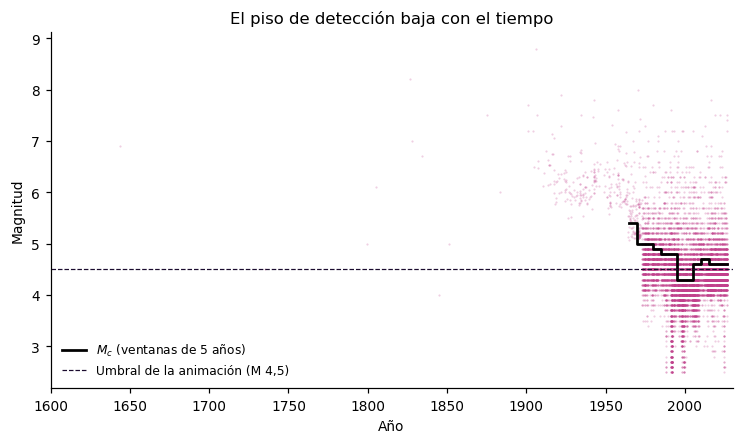

,1965,1970,1975,1980,1985,1990,1995,2000,2005,2010,2015,2020,2025
Mc,5.4,5.0,5.0,4.9,4.8,4.8,4.3,4.3,4.6,4.7,4.6,4.6,4.6


In [7]:
def mc_maxc(mags, paso=0.1, correccion=0.2, n_min=50):
    """Magnitud de completitud por máxima curvatura (Wiemer y Wyss, 2000)."""
    m = np.round(pd.Series(mags).dropna().to_numpy(), 1)
    if len(m) < n_min:
        return np.nan
    bordes = np.arange(m.min() - paso / 2, m.max() + paso, paso)
    h, _ = np.histogram(m, bins=bordes)
    return round(bordes[np.argmax(h)] + paso / 2 + correccion, 1)

inst = cat[~cat.historico]
ventanas = np.arange(1960, int(ANIO_FIN) + 1, 5)
mc = pd.Series({a: mc_maxc(inst.loc[inst.anio.between(a, a + 4), "mag"]) for a in ventanas}, name="Mc")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(cat.anio_dec, cat.mag, s=2, alpha=0.25, color="#c2408c", linewidths=0, rasterized=True)
ax.step(list(mc.index) + [ANIO_FIN], list(mc.values) + [mc.values[-1]], where="post", color="k", lw=1.8,
        label="$M_c$ (ventanas de 5 años)")
ax.axhline(MAG_COMPLETA, color="#1b0b2e", lw=0.8, ls="--", label=f"Umbral de la animación (M {dec(MAG_COMPLETA)})")
ax.set(xlim=(max(cat.anio.min() - 5, 1600), 2030), xlabel="Año", ylabel="Magnitud",
       title="El piso de detección baja con el tiempo")
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.savefig(FIG / "fig2_magnitud_tiempo.png"); plt.show()
mc.dropna().to_frame().T

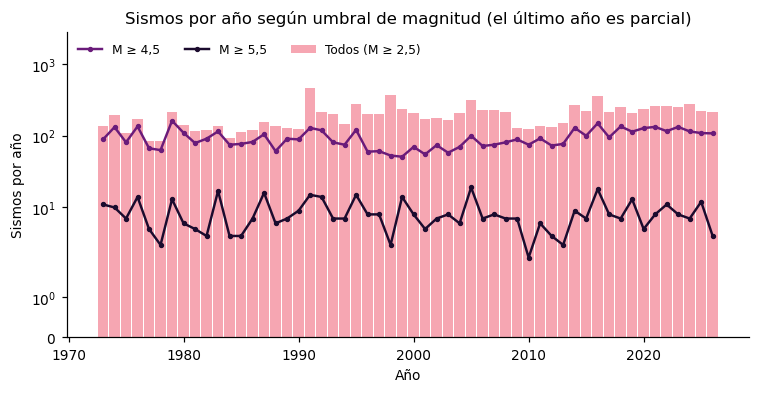

M ≥ 4,5 desde 1973: media 93.8 sismos/año, tendencia lineal +0.32 sismos/año por año


In [8]:
# Tasa anual desde 1973: si el umbral es completo, no debería haber tendencia instrumental
anios = np.arange(1973, int(ANIO_FIN) + 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
todos = inst.anio.value_counts().reindex(anios, fill_value=0)
ax.bar(anios, todos, color="#f6a6b2", width=0.9, label=f"Todos (M ≥ {dec(MAG_MIN)})")
for umbral, color in [(MAG_COMPLETA, "#6a1b7a"), (5.5, "#1b0b2e")]:
    serie = inst[inst.mag >= umbral].anio.value_counts().reindex(anios, fill_value=0)
    ax.plot(anios, serie, color=color, lw=1.6, marker="o", ms=2.5, label=f"M ≥ {dec(umbral)}")
ax.set(yscale="symlog", xlabel="Año", ylabel="Sismos por año", ylim=(0, max(todos.max(), 1) * 6),
       title="Sismos por año según umbral de magnitud (el último año es parcial)")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
fig.savefig(FIG / "fig3_tasa_anual.png"); plt.show()

sub = inst[(inst.mag >= MAG_COMPLETA) & (inst.anio >= 1973) & (inst.anio < int(ANIO_FIN))]
por_anio = sub.anio.value_counts().reindex(anios[:-1], fill_value=0)
pend = np.polyfit(por_anio.index, por_anio.values, 1)[0]
print(f"M ≥ {dec(MAG_COMPLETA)} desde 1973: media {por_anio.mean():.1f} sismos/año, "
      f"tendencia lineal {pend:+.2f} sismos/año por año")

## 4. Mapa

Misma codificación del video: el tamaño indica magnitud y el color, profundidad (escala saturada en 200 km). Tres diferencias deliberadas:

- Los sismos **sin profundidad conocida** se dibujan como anillos vacíos, no como superficiales.
- Los eventos grandes se dibujan primero para que no tapen a los pequeños.
- Se etiquetan los de mayor **magnitud** (negro) y los de mayor **número de víctimas** según NOAA (rojo).

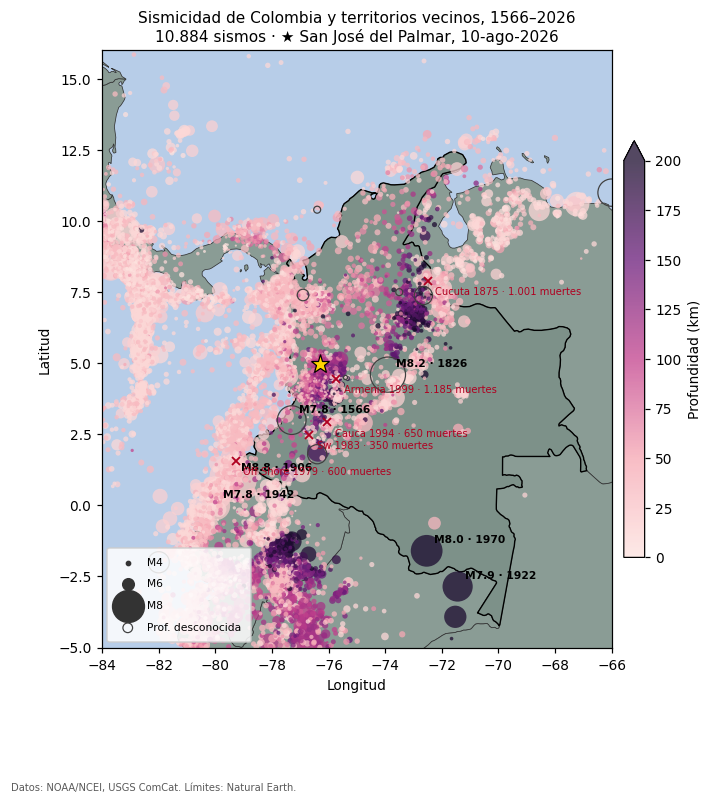

In [9]:
URL_PAISES = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/"
              "ne_50m_admin_0_countries.geojson")
archivo_paises = DATA / "paises_ne50m.geojson"
if not archivo_paises.exists():
    archivo_paises.write_bytes(requests.get(URL_PAISES, timeout=120).content)
paises = gpd.read_file(archivo_paises)
paises = paises.cx[BBOX["lon_min"] - 6:BBOX["lon_max"] + 6, BBOX["lat_min"] - 6:BBOX["lat_max"] + 6]
colombia = paises[paises["ADMIN"] == "Colombia"]

CMAP = LinearSegmentedColormap.from_list("profundidad", ["#fde3df", "#f6a6b2", "#c2408c", "#6a1b7a", "#1b0b2e"])
NORM = Normalize(0, PROF_MAX)

def tam(mag):
    """Área del marcador: crece exponencialmente con la magnitud (M2≈1, M4≈8, M6≈57, M8≈430)."""
    return 2.75 ** (np.clip(np.asarray(mag, dtype=float), 2, 9.5) - 2)

def mapa_base(ax):
    ax.set_facecolor("#b7cde8")
    paises.plot(ax=ax, color="#8a9c95", edgecolor="#333", linewidth=0.5)
    colombia.plot(ax=ax, color="#7d9189", edgecolor="k", linewidth=0.9)
    ax.set_xlim(BBOX["lon_min"], BBOX["lon_max"]); ax.set_ylim(BBOX["lat_min"], BBOX["lat_max"])
    ax.set_aspect(1 / np.cos(np.radians(LAT_MEDIA)))
    ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(True)

def leyenda_magnitud(ax, loc="lower left"):
    marcas = [ax.scatter([], [], s=tam(m), color="0.2", label=f"M{m}") for m in (4, 6, 8)]
    hueco = ax.scatter([], [], s=40, facecolors="none", edgecolors="0.25", linewidths=0.8,
                       label="Prof. desconocida")
    ax.legend(handles=marcas + [hueco], loc=loc, fontsize=7, frameon=True, framealpha=0.85,
              labelspacing=1.1, borderpad=0.9)

def dibujar_sismos(ax, df, alpha=0.75):
    df = df.sort_values("mag", ascending=False)             # grandes debajo
    con, sin = df[df.prof_km.notna()], df[df.prof_km.isna()]
    sc = ax.scatter(con.lon, con.lat, s=tam(con.mag), c=con.prof_km, cmap=CMAP, norm=NORM,
                    alpha=alpha, linewidths=0, rasterized=True)
    ax.scatter(sin.lon, sin.lat, s=tam(sin.mag), facecolors="none", edgecolors="0.25", linewidths=0.8)
    return sc

fig, ax = plt.subplots(figsize=(7.2, 8.2))
mapa_base(ax)
sc = dibujar_sismos(ax, cat)
fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.02, extend="max", label="Profundidad (km)")
leyenda_magnitud(ax)

for _, r in cat.nlargest(6, "mag").iterrows():                # etiquetas por magnitud
    ax.annotate(f"M{r.mag:.1f} · {r.anio}", (r.lon, r.lat), xytext=(5, 5), textcoords="offset points",
                fontsize=7, fontweight="bold")
if len(noaa) and noaa.muertes.notna().any():                   # etiquetas por impacto
    for _, r in noaa.dropna(subset=["muertes", "lat", "lon"]).nlargest(6, "muertes").iterrows():
        ax.plot(r.lon, r.lat, marker="x", color="#b00020", ms=5, mew=1.2)
        ax.annotate(f"{r.lugar} {int(r.anio_dec)} · {miles(r.muertes)} muertes", (r.lon, r.lat),
                    xytext=(5, -9), textcoords="offset points", fontsize=6.5, color="#b00020")
ax.plot(EVENTO_REF["lon"], EVENTO_REF["lat"], marker="*", ms=13, color="#ffd400", mec="k", mew=0.8)
ax.set_title(f"Sismicidad de Colombia y territorios vecinos, {cat.anio.min()}–{cat.anio.max()}\n"
             f"{miles(len(cat))} sismos · ★ {EVENTO_REF['nombre']}", fontsize=10)
fig.text(0.01, 0.005, f"{CREDITO} Límites: Natural Earth.", fontsize=6.5, color="0.35")
fig.savefig(FIG / "fig4_mapa.png"); plt.show()

## 5. Animación a ritmo constante

En el video original el reloj no avanza a velocidad constante y todos los eventos entran al mismo conteo. Aquí cada cuadro equivale al mismo número de años y los dos paneles comparten reloj: a la izquierda todo el catálogo (lo que muestra el reel) y a la derecha solo los sismos sobre el umbral completo. La advertencia va **dentro** de la imagen.

In [10]:
ANIM_INI = 1900       # @param {type:"integer"}
ANIOS_POR_CUADRO = 1  # @param {type:"number"}
FPS = 12              # @param {type:"integer"}

def animar(df, mag_completa=MAG_COMPLETA, anio_ini=ANIM_INI, paso=ANIOS_POR_CUADRO, fps=FPS):
    df = df[df.anio_dec >= anio_ini].sort_values("anio_dec")
    grupos = [df, df[df.mag >= mag_completa]]
    titulos = ["Todo el catálogo", f"Solo M ≥ {dec(mag_completa)}"]
    tiempos = np.append(np.arange(anio_ini, ANIO_FIN, paso), [ANIO_FIN] * fps)   # pausa final de 1 s

    fig, axs = plt.subplots(1, 2, figsize=(10, 6.3), dpi=90)
    cmap = CMAP.copy(); cmap.set_bad("0.35")
    capas = []
    for ax, g, titulo in zip(axs, grupos, titulos):
        mapa_base(ax); ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(labelsize=7)
        ax.set_title(titulo, fontsize=11, fontweight="bold")
        sc = ax.scatter([], [], s=[], c=[], cmap=cmap, norm=NORM, alpha=0.75, linewidths=0)
        txt = ax.text(0.03, 0.03, "", transform=ax.transAxes, fontsize=10,
                      bbox=dict(fc="white", ec="none", alpha=0.8))
        capas.append((sc, txt, g.anio_dec.to_numpy(), g[["lon", "lat"]].to_numpy(),
                      tam(g.mag), np.ma.masked_invalid(g.prof_km.to_numpy(dtype=float))))
    reloj = fig.suptitle("", fontsize=16, fontweight="bold", y=0.98)
    fig.text(0.5, 0.015, "El aumento del panel izquierdo refleja mejor monitoreo, no más actividad sísmica. "
             + CREDITO, ha="center", fontsize=8.5)
    fig.subplots_adjust(left=0.05, right=0.98, top=0.9, bottom=0.08, wspace=0.12)

    def actualizar(i):
        t = tiempos[i]
        for sc, txt, tt, xy, s, c in capas:
            k = np.searchsorted(tt, t, side="right")
            sc.set_offsets(xy[:k]); sc.set_sizes(s[:k]); sc.set_array(c[:k])
            txt.set_text(f"{miles(k)} sismos")
        reloj.set_text(str(int(t)))
        return [c[0] for c in capas]

    anim = animation.FuncAnimation(fig, actualizar, frames=len(tiempos), interval=1000 / fps)
    if animation.writers.is_available("ffmpeg"):
        salida = FIG / "animacion_sismicidad.mp4"
        anim.save(salida, writer=animation.FFMpegWriter(fps=fps, bitrate=1600))
    else:
        salida = FIG / "animacion_sismicidad.gif"
        anim.save(salida, writer=animation.PillowWriter(fps=fps))
    plt.close(fig)
    return salida

archivo_anim = animar(cat)
print("Animación guardada en", archivo_anim)

Animación guardada en figuras/animacion_sismicidad.gif


In [11]:
from IPython.display import Video, Image, display
if archivo_anim.suffix == ".mp4":
    display(Video(str(archivo_anim), embed=True, html_attributes="controls loop muted playsinline"))
else:
    display(Image(filename=str(archivo_anim)))

## 6. Cortes transversales

### 6.1 Réplica del video

Todo el cuadrante proyectado sobre un solo plano, hasta 200 km y con exageración vertical ×3. Se agregan la escala horizontal en kilómetros, los extremos rotulados y el sismo de referencia.

Dos advertencias de lectura. La exageración ×3 hace que una placa que buza 30° se vea a unos 60°. Y al proyectar más de 2.000 km de país sobre un plano, estructuras que están a cientos de kilómetros entre sí aparecen una al lado de la otra.

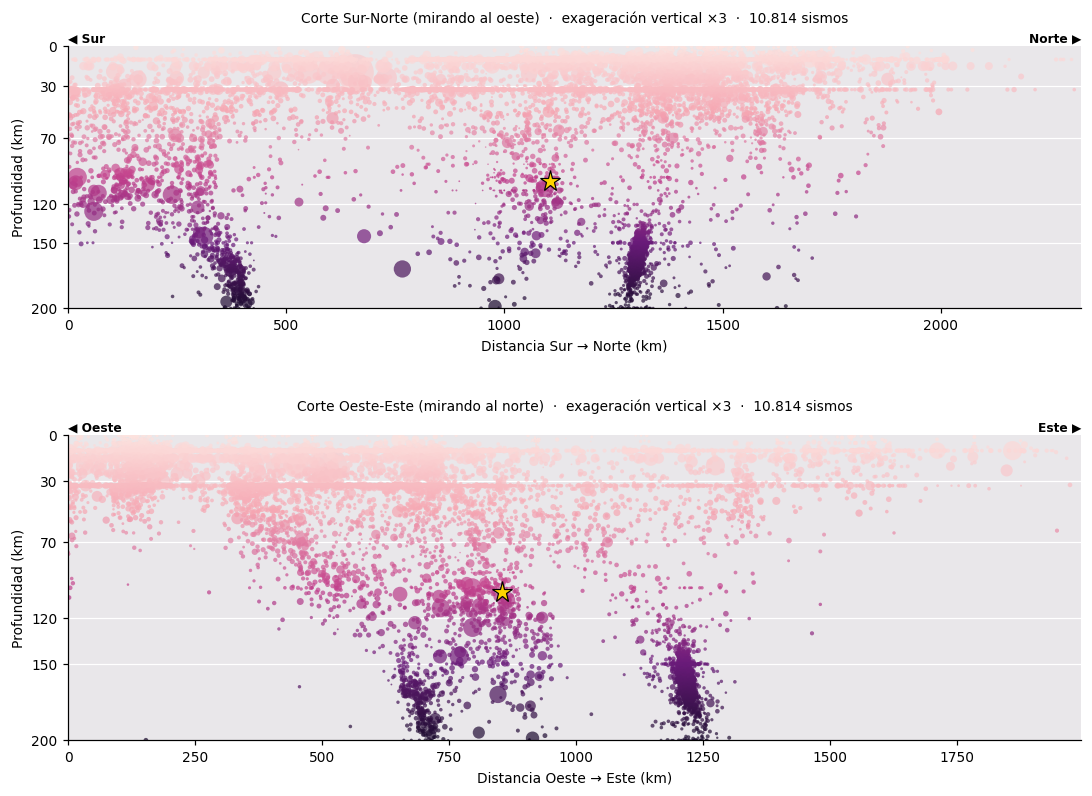

In [12]:
def corte(ax, df, eje="OE", banda=None, exag=EXAG_VERTICAL, lim=None, titulo=""):
    """Corte vertical. eje='OE' (mirando al norte) o 'SN' (mirando al oeste).
    banda=(min, max) limita la franja perpendicular al corte, en grados."""
    d = df[df.prof_km.notna() & (df.prof_km <= PROF_MAX)]
    if eje == "OE":
        if banda: d = d[d.lat.between(*banda)]
        h, origen, km, extremos = d.lon, BBOX["lon_min"], KM_LON, ("Oeste", "Este")
        lim = lim or (BBOX["lon_min"], BBOX["lon_max"]); ref = EVENTO_REF["lon"]
        en_banda = banda is None or banda[0] <= EVENTO_REF["lat"] <= banda[1]
    else:
        if banda: d = d[d.lon.between(*banda)]
        h, origen, km, extremos = d.lat, BBOX["lat_min"], KM_LAT, ("Sur", "Norte")
        lim = lim or (BBOX["lat_min"], BBOX["lat_max"]); ref = EVENTO_REF["lat"]
        en_banda = banda is None or banda[0] <= EVENTO_REF["lon"] <= banda[1]
    d = d.assign(h_km=(h - origen) * km).sort_values("mag", ascending=False)
    x0, x1 = [(v - origen) * km for v in lim]

    ax.set_facecolor("#e9e7ea")
    for z in (30, 70, 120, 150):
        ax.axhline(z, color="white", lw=0.8, zorder=0)
    ax.scatter(d.h_km, d.prof_km, s=tam(d.mag) * 0.6, c=d.prof_km, cmap=CMAP, norm=NORM,
               alpha=0.7, linewidths=0, rasterized=True)
    if en_banda and EVENTO_REF["prof_km"] <= PROF_MAX:
        ax.plot((ref - origen) * km, EVENTO_REF["prof_km"], marker="*", ms=14, color="#ffd400",
                mec="k", mew=0.8, zorder=5)
    ax.set_xlim(x0, x1); ax.set_ylim(PROF_MAX, 0); ax.set_aspect(exag)
    ax.set_yticks([0, 30, 70, 120, 150, PROF_MAX]); ax.set_ylabel("Profundidad (km)")
    ax.set_xlabel(f"Distancia {extremos[0]} → {extremos[1]} (km)")
    ax.annotate(f"◀ {extremos[0]}", (0, 1), xytext=(0, 3), xycoords="axes fraction",
                textcoords="offset points", fontsize=8, fontweight="bold")
    ax.annotate(f"{extremos[1]} ▶", (1, 1), xytext=(0, 3), xycoords="axes fraction",
                textcoords="offset points", fontsize=8, fontweight="bold", ha="right")
    ax.set_title(f"{titulo}  ·  exageración vertical ×{dec(exag)}  ·  {miles(len(d))} sismos",
                 fontsize=9, pad=16)
    return d

fig, axs = plt.subplots(2, 1, figsize=(10, 7.6))
corte(axs[0], cat, "SN", titulo="Corte Sur-Norte (mirando al oeste)")
corte(axs[1], cat, "OE", titulo="Corte Oeste-Este (mirando al norte)")
fig.tight_layout(); fig.savefig(FIG / "fig5_cortes_replica.png"); plt.show()

### 6.2 Cortes por franjas

En lugar de proyectar todo el país, se toman franjas de latitud. Así se separan los dos segmentos que el video superpone: el del **nido de Bucaramanga** y el del **occidente (Chocó–Eje Cafetero)**, donde ocurrió el sismo del 10 de agosto de 2026 (★). El último panel repite la franja occidental **sin exageración vertical** para mostrar la geometría real.

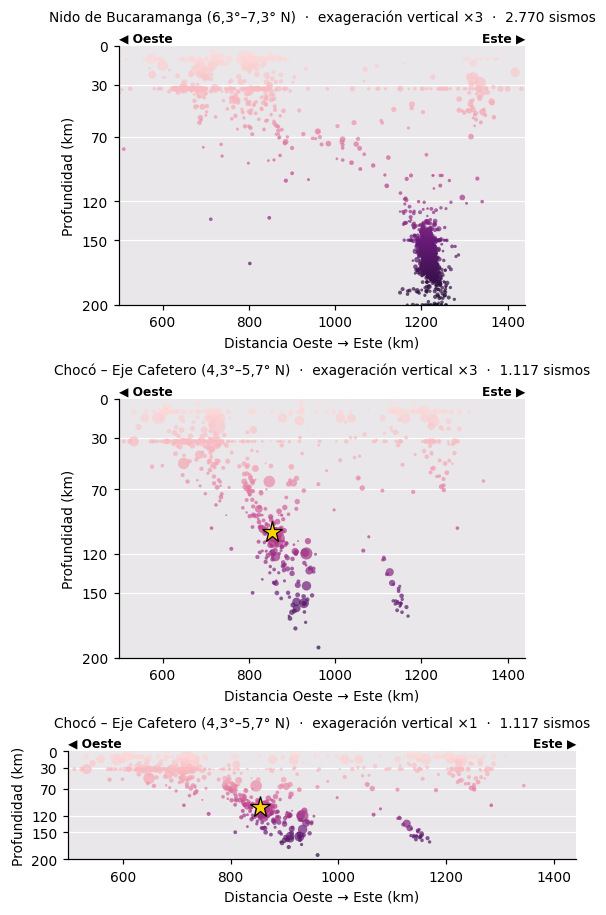

In [13]:
FRANJAS = {
    "Nido de Bucaramanga (6,3°–7,3° N)": (6.3, 7.3),
    "Chocó – Eje Cafetero (4,3°–5,7° N)": (4.3, 5.7),
}
LIM_LON = (-79.5, -71.0)
ancho_km = (LIM_LON[1] - LIM_LON[0]) * KM_LON

fig = plt.figure(figsize=(9, 9.6))
gs = fig.add_gridspec(3, 1, height_ratios=[EXAG_VERTICAL, EXAG_VERTICAL, 1.25], hspace=0.45)
for i, (nombre, banda) in enumerate(FRANJAS.items()):
    corte(fig.add_subplot(gs[i]), cat, "OE", banda=banda, lim=LIM_LON, titulo=nombre)
ultima = list(FRANJAS.items())[-1]
corte(fig.add_subplot(gs[2]), cat, "OE", banda=ultima[1], lim=LIM_LON, exag=1, titulo=ultima[0])
fig.savefig(FIG / "fig6_cortes_franjas.png"); plt.show()

## 7. Vista 3D interactiva

Equivalente al bloque 3D del video, pero manipulable. Se limita a M ≥ 4 y a 200 km para que sea liviana; el eje vertical conserva la exageración definida en los parámetros.

In [14]:
import plotly.graph_objects as go

d3 = cat[cat.prof_km.notna() & (cat.prof_km <= PROF_MAX) & (cat.mag >= 4.0)]
escala = [[i / 4, c] for i, c in enumerate(["#fde3df", "#f6a6b2", "#c2408c", "#6a1b7a", "#1b0b2e"])]

fig3d = go.Figure()
for geom in getattr(colombia.geometry.iloc[0], "geoms", [colombia.geometry.iloc[0]]):   # borde de Colombia
    x, y = geom.exterior.coords.xy
    fig3d.add_trace(go.Scatter3d(x=list(x), y=list(y), z=[0] * len(x), mode="lines",
                                 line=dict(color="black", width=3), hoverinfo="skip", showlegend=False))
fig3d.add_trace(go.Scatter3d(
    x=d3.lon, y=d3.lat, z=-d3.prof_km, mode="markers", showlegend=False,
    marker=dict(size=np.clip((d3.mag - 3) * 1.8, 1.5, 12), color=d3.prof_km, colorscale=escala, cmin=0,
                cmax=PROF_MAX, opacity=0.75, line=dict(width=0), colorbar=dict(title="Prof. (km)", len=0.6)),
    text=[f"M{m:.1f} · {f}<br>{p:.0f} km" for m, f, p in zip(d3.mag, d3.fecha, d3.prof_km)], hoverinfo="text"))
fig3d.add_trace(go.Scatter3d(x=[EVENTO_REF["lon"]], y=[EVENTO_REF["lat"]], z=[-EVENTO_REF["prof_km"]],
    mode="markers+text", text=["★ 10-ago-2026"], textposition="top center", showlegend=False,
    marker=dict(size=7, color="#ffd400", symbol="diamond", line=dict(color="black", width=2))))

dx = (BBOX["lon_max"] - BBOX["lon_min"]) * KM_LON
dy = (BBOX["lat_max"] - BBOX["lat_min"]) * KM_LAT
fig3d.update_layout(
    title=f"Sismicidad M ≥ 4 hasta {PROF_MAX} km · exageración vertical ×{dec(EXAG_VERTICAL)}",
    height=620, margin=dict(l=0, r=0, t=40, b=0),
    scene=dict(xaxis_title="Longitud", yaxis_title="Latitud", zaxis_title="Profundidad (km)",
               xaxis=dict(range=[BBOX["lon_min"], BBOX["lon_max"]]),
               yaxis=dict(range=[BBOX["lat_min"], BBOX["lat_max"]]), zaxis=dict(range=[-PROF_MAX, 0]),
               aspectmode="manual", aspectratio=dict(x=1, y=dy / dx, z=PROF_MAX * EXAG_VERTICAL / dx),
               camera=dict(eye=dict(x=-1.3, y=-1.6, z=0.9))))
fig3d.show()

## 8. Lectura y límites

**Qué se puede afirmar.** El crecimiento del número de sismos es un efecto de instrumentación: desaparece al filtrar por una magnitud completa. La sismicidad intermedia dibuja placas que se hunden hacia el este, con dos segmentos distintos, y el sismo del 10 de agosto de 2026 se ubica dentro del segmento occidental, a profundidad intermedia.

**Qué no.** Este cuaderno describe **amenaza**, no riesgo: no incluye exposición ni vulnerabilidad. La sismicidad cortical (la que más daño suele causar) queda mal representada en cortes a escala de país.

**Límites de los datos.**
- El catálogo del USGS es completo para la región solo desde magnitudes cercanas a 4,5; no reproduce los conteos del SGC.
- Mezcla tipos de magnitud (Mw, mb, ML, Ms) sin homogeneizar. El Catálogo Sísmico Integrado del SGC sí lo hace, hasta 2020.
- Muchas profundidades antiguas son valores fijos asignados por la agencia (10, 33, 35 km) y las incertidumbres en profundidad son mayores que las horizontales; la exageración vertical las amplifica.
- Las magnitudes históricas se derivan de intensidades y los eventos anteriores a 1900 dependen de lo que quedó documentado.
- La conversión de grados a kilómetros usa una aproximación plana con la latitud media del cuadrante.

## Referencias

- Montejo, J., Arcila, M. y Zornosa, D. (2023). Catálogo Sísmico Integrado para Colombia. *Boletín Geológico*, 50(1). https://doi.org/10.32685/0120-1425/bol.geol.50.1.2023.665
- NOAA National Centers for Environmental Information. *Global Significant Earthquake Database*. https://doi.org/10.7289/V5TD9V7K
- Servicio Geológico Colombiano. *Red Sismológica Nacional de Colombia* (red CM). https://doi.org/10.7914/SN/CM
- U.S. Geological Survey. *ANSS Comprehensive Earthquake Catalog (ComCat)*, servicio FDSN. https://earthquake.usgs.gov/fdsnws/event/1/
- Wiemer, S. y Wyss, M. (2000). Minimum magnitude of completeness in earthquake catalogs. *Bulletin of the Seismological Society of America*, 90(4), 859–869.
- Visualización original: @notasdeungeologo, Instagram, 29 de septiembre de 2026. https://www.instagram.com/reel/Dd4-gbFCZV3/

In [15]:
# Entorno de ejecución (para reproducibilidad)
import sys, plotly
print("Python", sys.version.split()[0])
for m in (np, pd, mpl, gpd, plotly, requests):
    print(f"{m.__name__:<12}{m.__version__}")
print("Ejecutado:", pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M UTC"))

Python 3.13.9
numpy       2.3.5
pandas      2.3.3
matplotlib  3.10.6
geopandas   1.1.4
plotly      6.3.0
requests    2.32.5
Ejecutado: 2026-10-05 20:23 UTC
